In [1]:
import pandas as pd
import sklearn

print("Notebook configurado com sucesso!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Notebook configurado com sucesso!
Pandas: 2.3.3
Scikit-learn: 1.9.1


# Issue #10 — Modelo dos fatores de longevidade

## 1. Análise exploratória dos dados

**Objetivo:** investigar quais características estão associadas à popularidade dos livros, comparando uma regressão linear com um modelo Random Forest.

**Fonte:** dados tratados do projeto Book Trends, coletados da Open Library e enriquecidos com informações do Google Books.

**Unidade de análise:** obra literária.

**Variável-alvo inicial:** `pct_leitores_periodo`, que representa a posição relativa de um livro em quantidade de leitores dentro do seu período de publicação.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Caminho da raiz do projeto
RAIZ = Path.cwd().parent

# Carregar dados
df = pd.read_csv(RAIZ / "processed" / "perfis_livros.csv")

# Visualizar as primeiras linhas
display(df.head())

print(f"Total de livros: {len(df):,}")
print(f"Total de variáveis: {len(df.columns)}")

,id_livro,titulo,titulo_exibicao,titulo_pt,titulo_pt_fonte,autor_principal,ano_publicacao,idade,genero_principal,genero_fonte,...,ganho_leitores,crescimento_pct,crescimento_pct_30d,periodo,pct_leitores_periodo,pct_edicoes_periodo,perfil,tem_pt,amostra,ids_agrupados
0,OL14962785W,Angel time,Angel time,NaN,NaN,Anne Rice,2009.0,17.0,Terror,automatico,...,NaN,NaN,NaN,2000s,0.021,0.789,Estável,False,NaN,OL14962785W
1,OL19681321W,The Red Fox Clan,The Red Fox Clan,NaN,NaN,John Flanagan,2018.0,8.0,Mistério,automatico,...,NaN,NaN,NaN,2010s,0.667,0.092,Estável,False,readinglog,OL19681321W
2,OL1174839W,They found Atlantis,They found Atlantis,NaN,NaN,Dennis Wheatley,1935.0,91.0,Fantasia,automatico,...,NaN,NaN,NaN,1930s,0.030,0.162,Estável,False,key,OL1174839W
3,OL1174844W,The Ka of Gifford Hillary,The Ka of Gifford Hillary,NaN,NaN,Dennis Wheatley,1956.0,70.0,Terror,automatico,...,NaN,NaN,NaN,1950s,0.025,0.421,Estável,False,key,OL1174844W
4,OL1174847W,Strange conflict,Strange conflict,NaN,NaN,Dennis Wheatley,1941.0,85.0,Terror,automatico,...,NaN,NaN,NaN,1940s,0.031,0.178,Estável,False,key,OL1174847W


Total de livros: 9,241
Total de variáveis: 32


### 1.1 Estatísticas descritivas

Nesta etapa, analisamos a distribuição das principais variáveis numéricas para identificar diferenças de escala, valores extremos e características que precisam de tratamento antes da modelagem.

In [3]:
# Variáveis numéricas relevantes para a modelagem
variaveis_numericas = [
    "idade",
    "qtd_edicoes",
    "nota_media",
    "qtd_avaliacoes",
    "leitores",
    "pct_leitores_periodo"
]

# Estatísticas descritivas
estatisticas = df[variaveis_numericas].describe().T

# Adicionar a mediana para facilitar a comparação
estatisticas["mediana"] = df[variaveis_numericas].median()

display(estatisticas.round(2))

,count,mean,std,min,25%,50%,75%,max,mediana
idade,9241.0,52.74,67.74,6.0,20.00,33.0,57.00,1026.0,33.0
qtd_edicoes,9241.0,56.08,185.88,1.0,7.00,17.0,36.00,6116.0,17.0
nota_media,8890.0,4.00,0.59,1.0,3.71,4.0,4.33,5.0,4.0
qtd_avaliacoes,9241.0,16.87,43.41,0.0,3.00,7.0,15.00,1242.0,7.0
leitores,9241.0,225.37,973.39,0.0,63.00,89.0,159.00,53035.0,89.0
pct_leitores_periodo,9241.0,0.50,0.29,0.0,0.25,0.5,0.75,1.0,0.5


### 1.2 Distribuição das variáveis

As estatísticas descritivas indicam assimetria nas distribuições de edições, avaliações e leitores. Nesta seção, comparamos as distribuições originais com transformações logarítmicas para avaliar a concentração de observações e a presença de valores extremos.

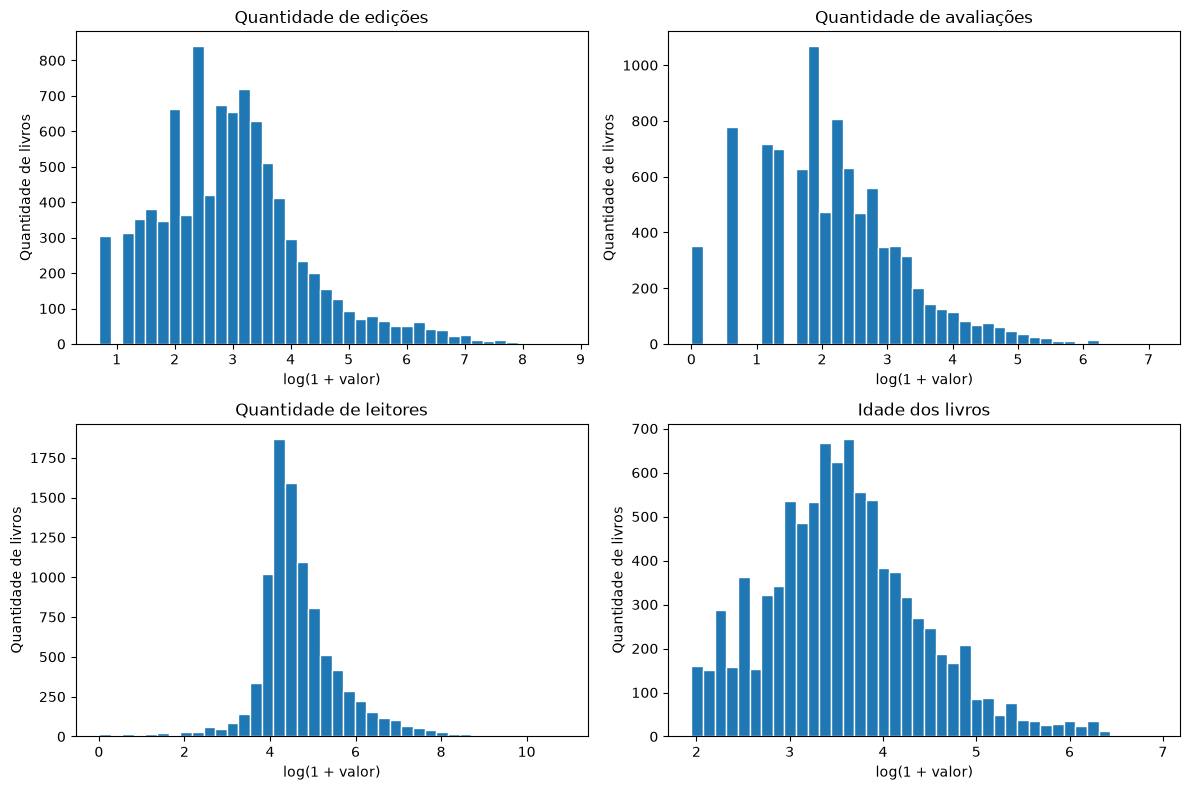

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

variaveis = [
    ("qtd_edicoes", "Quantidade de edições"),
    ("qtd_avaliacoes", "Quantidade de avaliações"),
    ("leitores", "Quantidade de leitores"),
    ("idade", "Idade dos livros")
]

for ax, (coluna, titulo) in zip(axes.flat, variaveis):
    valores = np.log1p(df[coluna].clip(lower=0))

    ax.hist(valores, bins=40, edgecolor="white")
    ax.set_title(titulo)
    ax.set_xlabel("log(1 + valor)")
    ax.set_ylabel("Quantidade de livros")

plt.tight_layout()
plt.show()

### 1.3 Correlação entre as variáveis

Nesta etapa, investigamos a associação entre as características numéricas dos livros e sua posição relativa de popularidade dentro do período de publicação.

Utilizamos a correlação de Spearman, que mede associações monotônicas e é menos sensível a valores extremos do que a correlação de Pearson.

Correlação não implica causalidade.

In [5]:
# Selecionar variáveis para a análise de correlação
colunas_correlacao = [
    "idade",
    "qtd_edicoes",
    "nota_media",
    "qtd_avaliacoes",
    "pct_leitores_periodo"
]

# Calcular correlação de Spearman
matriz_correlacao = df[colunas_correlacao].corr(method="spearman")

# Visualizar a matriz
display(matriz_correlacao.round(3))

# Destacar associações com a variável-alvo
correlacoes_alvo = (
    matriz_correlacao["pct_leitores_periodo"]
    .drop("pct_leitores_periodo")
    .sort_values(ascending=False)
)

display(correlacoes_alvo.to_frame("Correlacao com popularidade"))

,idade,qtd_edicoes,nota_media,qtd_avaliacoes,pct_leitores_periodo
idade,1.000,0.515,-0.084,-0.108,0.005
qtd_edicoes,0.515,1.000,-0.067,0.179,0.184
nota_media,-0.084,-0.067,1.000,-0.049,0.051
qtd_avaliacoes,-0.108,0.179,-0.049,1.000,0.653
pct_leitores_periodo,0.005,0.184,0.051,0.653,1.000


,Correlacao com popularidade
qtd_avaliacoes,0.653302
qtd_edicoes,0.184450
nota_media,0.051316
idade,0.005346


## 2. Preparação dos dados para modelagem

Nesta etapa, selecionamos a variável-alvo e as características explicativas utilizadas na regressão linear e na Random Forest.

O alvo inicial é `pct_leitores_periodo`, que mede a posição relativa de popularidade de cada obra dentro do seu período de publicação.

Os valores ausentes, a codificação das variáveis categóricas e as transformações numéricas serão tratados dentro dos pipelines de modelagem, utilizando apenas o conjunto de treinamento para ajustar os parâmetros de pré-processamento.

In [6]:
# Variável que queremos explicar
alvo = "pct_leitores_periodo"

# Características dos livros
variaveis_modelo = [
    "idade",
    "qtd_edicoes",
    "nota_media",
    "qtd_avaliacoes",
    "genero_principal",
    "tem_pt"
]

# Criar uma base somente com as colunas necessárias
dados_modelo = df[variaveis_modelo + [alvo]].copy()

# Conferir os tipos
print("Tipos das variáveis:")
print(dados_modelo.dtypes)

print("\nValores ausentes:")
print(dados_modelo.isna().sum())

print("\nPrimeiras observações:")
display(dados_modelo.head())

Tipos das variáveis:
idade                   float64
qtd_edicoes               int64
nota_media              float64
qtd_avaliacoes            int64
genero_principal         object
tem_pt                     bool
pct_leitores_periodo    float64
dtype: object

Valores ausentes:
idade                     0
qtd_edicoes               0
nota_media              351
qtd_avaliacoes            0
genero_principal          0
tem_pt                    0
pct_leitores_periodo      0
dtype: int64

Primeiras observações:


,idade,qtd_edicoes,nota_media,qtd_avaliacoes,genero_principal,tem_pt,pct_leitores_periodo
0,17.0,27,3.00,2,Terror,False,0.021
1,8.0,2,4.88,8,Mistério,False,0.667
2,91.0,23,NaN,0,Fantasia,False,0.030
3,70.0,28,NaN,0,Terror,False,0.025
4,85.0,20,NaN,0,Terror,False,0.031


### 2.1 Separação dos conjuntos de treinamento e teste

A base será dividida em 80% para treinamento e 20% para teste.

Essa estratégia permite avaliar o desempenho dos modelos em observações que não participaram do treinamento.

A divisão utiliza `random_state=42` para garantir reprodutibilidade. Os mesmos conjuntos serão usados na regressão linear e na Random Forest.

In [7]:
from sklearn.model_selection import train_test_split

# Separar as variáveis explicativas do alvo
X = dados_modelo[variaveis_modelo]
y = dados_modelo[alvo]

# Dividir os dados em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

print("\nAlvo no treinamento:")
print(y_treino.describe().round(3))

print("\nAlvo no teste:")
print(y_teste.describe().round(3))

Treinamento: (7392, 6)
Teste: (1849, 6)

Alvo no treinamento:
count    7392.000
mean        0.503
std         0.288
min         0.001
25%         0.253
50%         0.504
75%         0.754
max         1.000
Name: pct_leitores_periodo, dtype: float64

Alvo no teste:
count    1849.000
mean        0.492
std         0.290
min         0.002
25%         0.240
50%         0.488
75%         0.742
max         1.000
Name: pct_leitores_periodo, dtype: float64


### 2.2 Pré-processamento das variáveis

O pré-processamento será realizado com `Pipeline` e `ColumnTransformer` do Scikit-learn.

Serão aplicados os seguintes tratamentos:

- Transformação `log1p` nas quantidades de edições e avaliações.
- Imputação pela mediana para os valores ausentes de nota média.
- Padronização das variáveis numéricas.
- Codificação One-Hot para o gênero literário.
- Preservação da variável booleana `tem_pt`.

Os parâmetros de pré-processamento serão ajustados exclusivamente com os dados de treinamento, evitando vazamento de informação do conjunto de teste.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer

# Variáveis numéricas com transformação logarítmica
pipeline_log = Pipeline([
    ("log", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("padronizar", StandardScaler())
])

# Variáveis numéricas sem transformação logarítmica
pipeline_numerico = Pipeline([
    ("preencher_ausentes", SimpleImputer(strategy="median")),
    ("padronizar", StandardScaler())
])

# Variáveis categóricas
pipeline_categorico = Pipeline([
    ("one_hot", OneHotEncoder(handle_unknown="ignore"))
])

# Combinar as transformações
preprocessador = ColumnTransformer([
    ("log", pipeline_log, ["qtd_edicoes", "qtd_avaliacoes"]),
    ("numerico", pipeline_numerico, ["idade", "nota_media"]),
    ("categorico", pipeline_categorico, ["genero_principal"]),
    ("booleano", "passthrough", ["tem_pt"])
])

print("Pré-processador configurado com sucesso!")

Pré-processador configurado com sucesso!


## 3. Modelagem estatística

### 3.1 Regressão linear

A regressão linear será utilizada como modelo de referência para investigar a associação entre as características das obras e sua posição relativa de popularidade.

O modelo combina as variáveis explicativas em uma função linear. Os coeficientes permitem analisar a direção e a magnitude das associações, considerando as transformações e a padronização aplicadas às variáveis.

O desempenho será avaliado no conjunto de teste, utilizando R², erro absoluto médio (MAE) e raiz do erro quadrático médio (RMSE).

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Combinar o pré-processamento com a regressão linear
modelo_linear = Pipeline([
    ("preprocessamento", preprocessador),
    ("regressao", LinearRegression())
])

# Treinar somente com os dados de treinamento
modelo_linear.fit(X_treino, y_treino)

# Fazer previsões para os livros do conjunto de teste
previsoes_linear = modelo_linear.predict(X_teste)

# Calcular métricas de desempenho
r2_linear = r2_score(y_teste, previsoes_linear)
mae_linear = mean_absolute_error(y_teste, previsoes_linear)
rmse_linear = np.sqrt(
    mean_squared_error(y_teste, previsoes_linear)
)

print("RESULTADOS — REGRESSÃO LINEAR")
print(f"R²:   {r2_linear:.4f}")
print(f"MAE:  {mae_linear:.4f}")
print(f"RMSE: {rmse_linear:.4f}")

RESULTADOS — REGRESSÃO LINEAR
R²:   0.4811
MAE:  0.1693
RMSE: 0.2085


### 3.2 Random Forest Regressor

A Random Forest é um método de aprendizado de máquina baseado na combinação de múltiplas árvores de decisão.

Diferentemente da regressão linear, pode representar relações não lineares e interações entre as características dos livros.

Será utilizada a mesma divisão de treinamento e teste da regressão linear, permitindo comparar os modelos por R², MAE e RMSE.

Nesta primeira versão, utilizamos hiperparâmetros definidos previamente, sem otimização com os dados de teste.

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

# Criar modelo de Random Forest
modelo_floresta = Pipeline([
    ("preprocessamento", clone(preprocessador)),
    ("random_forest", RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Treinar usando o mesmo conjunto de treinamento
modelo_floresta.fit(X_treino, y_treino)

# Prever a popularidade relativa no conjunto de teste
previsoes_floresta = modelo_floresta.predict(X_teste)

# Calcular as métricas
r2_floresta = r2_score(y_teste, previsoes_floresta)
mae_floresta = mean_absolute_error(y_teste, previsoes_floresta)
rmse_floresta = np.sqrt(
    mean_squared_error(y_teste, previsoes_floresta)
)

print("RESULTADOS — RANDOM FOREST")
print(f"R²:   {r2_floresta:.4f}")
print(f"MAE:  {mae_floresta:.4f}")
print(f"RMSE: {rmse_floresta:.4f}")

RESULTADOS — RANDOM FOREST
R²:   0.5856
MAE:  0.1461
RMSE: 0.1863


## 4. Importância das variáveis

Nesta etapa, investigamos quais características mais contribuem para o desempenho da Random Forest.

Utilizamos Permutation Importance, que mede a redução do R² quando os valores de uma variável são embaralhados.

Quanto maior a queda de desempenho, maior a importância preditiva da variável para o modelo.

Essa medida não representa causalidade e pode ser influenciada pela correlação entre as características.

,variavel,importancia_media,desvio_padrao
3,qtd_avaliacoes,1.0479,0.0343
1,qtd_edicoes,0.1212,0.0097
4,genero_principal,0.1167,0.0070
0,idade,0.0447,0.0033
2,nota_media,0.0248,0.0046
5,tem_pt,0.0212,0.0012


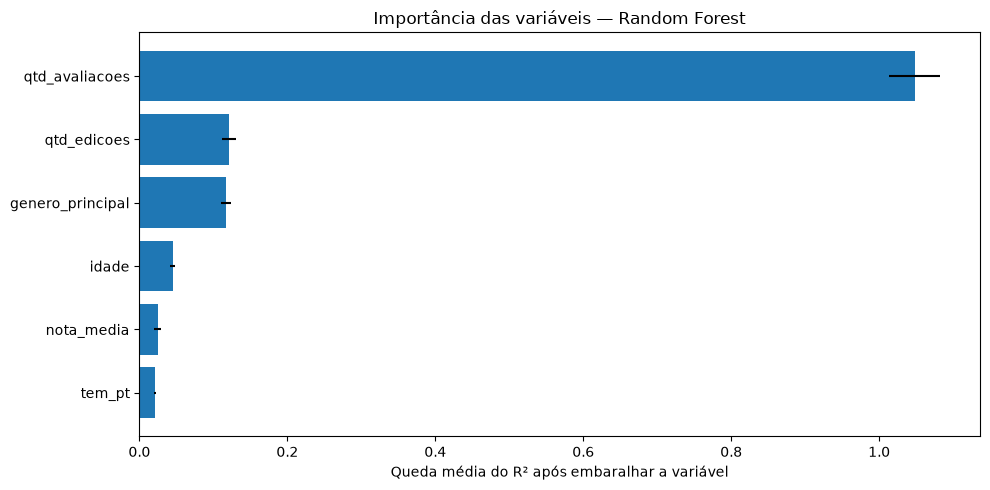

In [11]:
from sklearn.inspection import permutation_importance

# Calcular importância das variáveis no conjunto de teste
resultado_importancia = permutation_importance(
    modelo_floresta,
    X_teste,
    y_teste,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

# Organizar os resultados
importancia_df = pd.DataFrame({
    "variavel": X_teste.columns,
    "importancia_media": resultado_importancia.importances_mean,
    "desvio_padrao": resultado_importancia.importances_std
})

importancia_df = importancia_df.sort_values(
    "importancia_media",
    ascending=False
)

display(importancia_df.round(4))

# Visualizar as importâncias
plt.figure(figsize=(10, 5))

plt.barh(
    importancia_df["variavel"],
    importancia_df["importancia_media"],
    xerr=importancia_df["desvio_padrao"]
)

plt.gca().invert_yaxis()
plt.xlabel("Queda média do R² após embaralhar a variável")
plt.title("Importância das variáveis — Random Forest")
plt.tight_layout()
plt.show()

### 4.1 Análise de robustez — modelo sem quantidade de avaliações

Como a quantidade de avaliações apresentou importância preditiva dominante, realizamos um experimento adicional excluindo essa variável.

O objetivo é investigar quanto do desempenho da Random Forest permanece quando retiramos um indicador diretamente associado à atividade dos leitores.

Utilizamos a mesma divisão de treinamento e teste e os mesmos hiperparâmetros do modelo original.

Este experimento avalia a dependência preditiva do modelo, não o efeito causal das avaliações sobre a popularidade.

In [12]:
# Retirar a quantidade de avaliações
variaveis_sem_avaliacoes = [
    coluna for coluna in variaveis_modelo
    if coluna != "qtd_avaliacoes"
]

# Selecionar as mesmas observações de treino e teste
X_treino_reduzido = X_treino[variaveis_sem_avaliacoes]
X_teste_reduzido = X_teste[variaveis_sem_avaliacoes]

# Criar novo pré-processador sem a variável excluída
preprocessador_reduzido = ColumnTransformer([
    ("log", clone(pipeline_log), ["qtd_edicoes"]),
    ("numerico", clone(pipeline_numerico), ["idade", "nota_media"]),
    ("categorico", clone(pipeline_categorico), ["genero_principal"]),
    ("booleano", "passthrough", ["tem_pt"])
])

# Criar nova Random Forest com os mesmos parâmetros
modelo_floresta_reduzido = Pipeline([
    ("preprocessamento", preprocessador_reduzido),
    ("random_forest", RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Treinar e prever
modelo_floresta_reduzido.fit(
    X_treino_reduzido,
    y_treino
)

previsoes_reduzidas = modelo_floresta_reduzido.predict(
    X_teste_reduzido
)

# Avaliar
r2_reduzido = r2_score(y_teste, previsoes_reduzidas)
mae_reduzido = mean_absolute_error(y_teste, previsoes_reduzidas)
rmse_reduzido = np.sqrt(
    mean_squared_error(y_teste, previsoes_reduzidas)
)

# Comparação
comparacao = pd.DataFrame({
    "Modelo": [
        "Random Forest completa",
        "Random Forest sem avaliações"
    ],
    "R²": [r2_floresta, r2_reduzido],
    "MAE": [mae_floresta, mae_reduzido],
    "RMSE": [rmse_floresta, rmse_reduzido]
})

display(comparacao.round(4))

,Modelo,R²,MAE,RMSE
0,Random Forest completa,0.5856,0.1461,0.1863
1,Random Forest sem avaliações,0.3387,0.1944,0.2354


## 5. Interpretação da regressão linear

Nesta etapa, analisamos os coeficientes estimados pela regressão linear.

Como as variáveis numéricas foram padronizadas, os coeficientes representam a variação esperada no alvo associada ao aumento de uma unidade padronizada da respectiva variável, mantendo as demais constantes.

Para variáveis categóricas codificadas por One-Hot Encoding, a interpretação exige atenção à codificação e à categoria de referência.

Os coeficientes descrevem associações condicionais, não efeitos causais.

In [13]:
# Recuperar os nomes das variáveis após o pré-processamento
nomes_variaveis = (
    modelo_linear
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)

# Recuperar os coeficientes da regressão
coeficientes = (
    modelo_linear
    .named_steps["regressao"]
    .coef_
)

# Organizar em tabela
coeficientes_df = pd.DataFrame({
    "variavel": nomes_variaveis,
    "coeficiente": coeficientes
})

# Ordenar pela magnitude absoluta
coeficientes_df["magnitude"] = (
    coeficientes_df["coeficiente"].abs()
)

coeficientes_df = coeficientes_df.sort_values(
    "magnitude",
    ascending=False
)

display(coeficientes_df.round(4))

,variavel,coeficiente,magnitude
1,log__qtd_avaliacoes,0.1979,0.1979
8,categorico__genero_principal_História,0.1044,0.1044
6,categorico__genero_principal_Ficção científica,-0.0902,0.0902
9,categorico__genero_principal_Infantil,-0.0804,0.0804
13,categorico__genero_principal_Terror,0.0728,0.0728
4,categorico__genero_principal_Biografia,0.0609,0.0609
10,categorico__genero_principal_Mistério,-0.0448,0.0448
7,categorico__genero_principal_Ficção literária,-0.0403,0.0403
5,categorico__genero_principal_Fantasia,-0.0348,0.0348
12,categorico__genero_principal_Romance,0.0333,0.0333


### 5.1 Regressão linear com categoria de referência

Para tornar os coeficientes dos gêneros interpretáveis, ajustamos uma segunda regressão linear utilizando codificação One-Hot com uma categoria omitida.

O gênero de referência será Romance.

Os coeficientes dos demais gêneros representarão diferenças condicionais em relação a Romance, mantendo constantes as demais características incluídas no modelo.

O modelo continua sendo associativo, não causal.

In [14]:
# Criar codificador com Romance como categoria de referência
categorias_genero = sorted(
    X_treino["genero_principal"].dropna().unique()
)

categorias_genero = [
    "Romance"
] + [
    genero for genero in categorias_genero
    if genero != "Romance"
]

# Novo pré-processamento
preprocessador_interpretavel = ColumnTransformer([
    ("log", clone(pipeline_log), ["qtd_edicoes", "qtd_avaliacoes"]),
    ("numerico", clone(pipeline_numerico), ["idade", "nota_media"]),
    ("categorico", OneHotEncoder(
        categories=[categorias_genero],
        drop="first",
        handle_unknown="ignore"
    ), ["genero_principal"]),
    ("booleano", "passthrough", ["tem_pt"])
])

# Regressão com categoria de referência
modelo_linear_interpretavel = Pipeline([
    ("preprocessamento", preprocessador_interpretavel),
    ("regressao", LinearRegression())
])

modelo_linear_interpretavel.fit(X_treino, y_treino)

# Extrair coeficientes
nomes = (
    modelo_linear_interpretavel
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)

valores = (
    modelo_linear_interpretavel
    .named_steps["regressao"]
    .coef_
)

tabela_coeficientes = pd.DataFrame({
    "Variável": nomes,
    "Coeficiente": valores
})

display(
    tabela_coeficientes
    .sort_values("Coeficiente", ascending=False)
    .round(4)
)

# Conferir o desempenho
previsoes_interpretavel = modelo_linear_interpretavel.predict(X_teste)

print(
    "R² do modelo interpretável:",
    round(r2_score(y_teste, previsoes_interpretavel), 4)
)

,Variável,Coeficiente
1,log__qtd_avaliacoes,0.1979
8,categorico__genero_principal_História,0.0711
12,categorico__genero_principal_Terror,0.0395
0,log__qtd_edicoes,0.0294
4,categorico__genero_principal_Biografia,0.0277
3,numerico__nota_media,0.0162
2,numerico__idade,-0.0114
11,categorico__genero_principal_Não ficção,-0.0142
13,booleano__tem_pt,-0.0290
5,categorico__genero_principal_Fantasia,-0.0681


R² do modelo interpretável: 0.4811


### 5.2 Diagnóstico das previsões

Como a variável-alvo representa uma posição relativa entre 0 e 1, verificamos se os modelos produziram previsões fora desse intervalo.

Também analisamos os resíduos para identificar possíveis erros sistemáticos.

Esses diagnósticos ajudam a avaliar a adequação dos modelos e suas limitações.

In [15]:
# Verificar previsões fora do intervalo permitido
diagnostico = pd.DataFrame({
    "Modelo": ["Regressão linear", "Random Forest"],
    "Previsão mínima": [
        previsoes_interpretavel.min(),
        previsoes_floresta.min()
    ],
    "Previsão máxima": [
        previsoes_interpretavel.max(),
        previsoes_floresta.max()
    ],
    "Previsões abaixo de 0": [
        (previsoes_interpretavel < 0).sum(),
        (previsoes_floresta < 0).sum()
    ],
    "Previsões acima de 1": [
        (previsoes_interpretavel > 1).sum(),
        (previsoes_floresta > 1).sum()
    ]
})

display(diagnostico.round(4))

,Modelo,Previsão mínima,Previsão máxima,Previsões abaixo de 0,Previsões acima de 1
0,Regressão linear,-0.0121,1.3073,1,28
1,Random Forest,0.0174,0.9988,0,0


### 5.3 Análise dos resíduos

Os resíduos representam a diferença entre o valor observado e a previsão do modelo.

Nesta etapa, investigamos se existem padrões sistemáticos nos erros da regressão linear e da Random Forest.

Em particular, verificamos se os modelos tendem a superestimar livros pouco populares ou subestimar livros com elevada popularidade relativa.

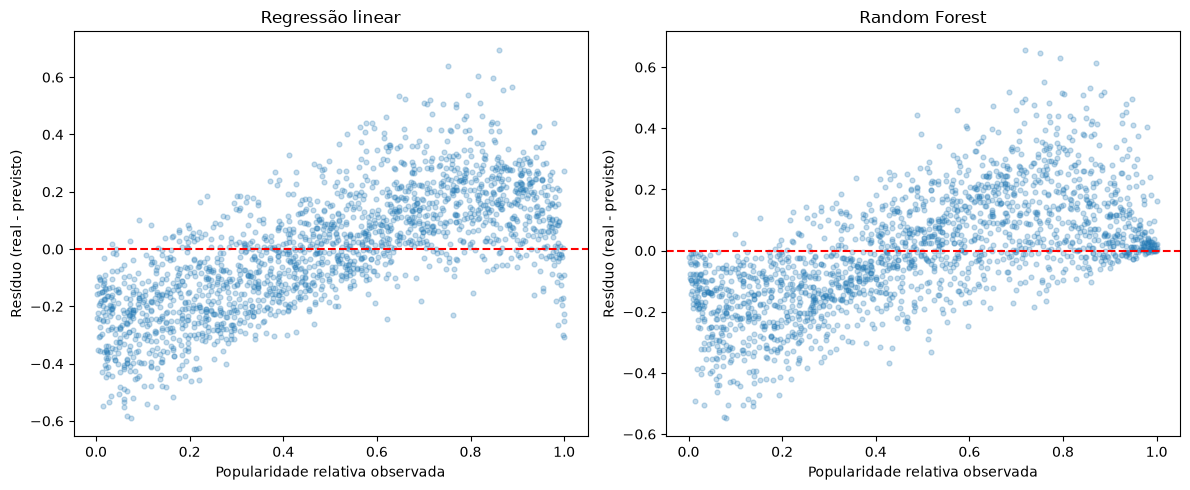

In [16]:
# Calcular os resíduos
residuos_linear = y_teste - previsoes_interpretavel
residuos_floresta = y_teste - previsoes_floresta

# Gráficos dos resíduos em função dos valores observados
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    y_teste,
    residuos_linear,
    alpha=0.25,
    s=12
)
axes[0].axhline(0, linestyle="--", color="red")
axes[0].set_title("Regressão linear")
axes[0].set_xlabel("Popularidade relativa observada")
axes[0].set_ylabel("Resíduo (real - previsto)")

axes[1].scatter(
    y_teste,
    residuos_floresta,
    alpha=0.25,
    s=12
)
axes[1].axhline(0, linestyle="--", color="red")
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Popularidade relativa observada")
axes[1].set_ylabel("Resíduo (real - previsto)")

plt.tight_layout()
plt.show()

## 6. Comparação e síntese dos modelos

Comparamos a regressão linear, a Random Forest completa e a Random Forest sem a quantidade de avaliações.

A análise considera as métricas R², MAE e RMSE, calculadas sobre o mesmo conjunto de teste.

Também avaliamos as limitações associadas ao alvo, à seleção da amostra e às características observadas simultaneamente à popularidade dos livros.

In [17]:
# Consolidar os resultados dos três modelos
resultados_finais = pd.DataFrame({
    "Modelo": [
        "Regressão linear",
        "Random Forest",
        "Random Forest sem avaliações"
    ],
    "R²": [
        r2_linear,
        r2_floresta,
        r2_reduzido
    ],
    "MAE": [
        mae_linear,
        mae_floresta,
        mae_reduzido
    ],
    "RMSE": [
        rmse_linear,
        rmse_floresta,
        rmse_reduzido
    ]
})

display(resultados_finais.round(4))

# Diferença de desempenho entre os modelos principais
print(
    "Ganho de R² da Random Forest:",
    round(r2_floresta - r2_linear, 4)
)

print(
    "Redução percentual do MAE:",
    round((mae_linear - mae_floresta) / mae_linear * 100, 2),
    "%"
)

,Modelo,R²,MAE,RMSE
0,Regressão linear,0.4811,0.1693,0.2085
1,Random Forest,0.5856,0.1461,0.1863
2,Random Forest sem avaliações,0.3387,0.1944,0.2354


Ganho de R² da Random Forest: 0.1045
Redução percentual do MAE: 13.74 %


## 7. Conclusões

A análise investigou associações entre características editoriais e a popularidade relativa de 9.241 obras literárias, utilizando regressão linear e Random Forest.

### Principais resultados

1. **Superioridade da Random Forest:** o modelo apresentou R² de 0,5856, contra 0,4811 da regressão linear, além de reduzir o MAE em 13,74%.

2. **Importância das avaliações:** `qtd_avaliacoes` foi a variável de maior importância preditiva. Entretanto, avaliações e leitores podem refletir a mesma popularidade subjacente, impedindo uma interpretação causal.

3. **Contribuição das características editoriais:** quantidade de edições e gênero literário também contribuíram para as previsões, embora com importância inferior à das avaliações.

4. **Robustez limitada sem avaliações:** a exclusão dessa variável reduziu o R² da Random Forest para 0,3387, demonstrando que parte significativa do desempenho depende de um indicador contemporâneo de popularidade.

5. **Limitações metodológicas:** os modelos explicam a posição relativa de popularidade na amostra observada, mas não comprovam capacidade de prever longevidade futura. Há limitações relacionadas à seleção dos livros, classificação dos gêneros, dependência entre indicadores e erros sistemáticos nas previsões extremas.

### Síntese

Os resultados mostram que métricas de engajamento e características editoriais contêm informações relevantes sobre a popularidade relativa dos livros. A Random Forest apresentou melhor desempenho, mas a identificação dos fatores que efetivamente sustentam a longevidade literária exige acompanhamento temporal e validações adicionais.